# Занятие 7. Кинематика летающих роботов — демонстрации

Конспект: лекция 7 (разделы 7.1–7.9). Модуль `aerial.py` (расчётные функции и рисование корпуса), цвета — из `kinlib.py`.
Соглашения лекции: ось $z$ вверх, связанные оси «вперёд — влево — вверх», углы 3-2-1 $R=R_z(\psi)R_y(\theta)R_x(\phi)$, кватернион $\mathbf e=(e_0,e_1,e_2,e_3)$ со скалярной частью первой, аппарат Hummingbird ($m=0{,}5$ кг, $L=0{,}175$ м, $\kappa=0{,}02455$ м). Все числа сверяются с примерами 7.1–7.7 конспекта.

| № | Демонстрация | Слайды | Конспект |
|---|---|---|---|
| 1 | Матрица поворота по углам 3-2-1 и пересчёт скорости из связанной системы в инерциальную | 6–8 | § 7.2, пример 7.1 |
| 2 | Матрица $W$ и её вырождение при тангаже $90^\circ$ | 12–15 | § 7.3, пример 7.2 |
| 3 | Счисление ориентации углами Эйлера, матрицей поворота и кватернионом | 16–18 | § 7.4 |
| 4 | Матрица смешивания квадрокоптера «X», её обращение и насыщение моторов | 26–28, 30–31 | § 7.5, примеры 7.3, 7.4 |
| 5 | Полёт квадрокоптера по модели «наклон — ускорение» с каскадным регулятором | 32–34 | § 7.6, пример 7.5 |
| 6 | Координированный разворот самолёта | 37, 40–41 | § 7.7 |
| 7 | Треугольник скоростей и снос ветром | 36 | § 7.7, пример 7.6 |
| 8 | Пути Дубинса между двумя позами | 38–39 | § 7.7, пример 7.7 |
| 9 | Отказ мотора у квадрокоптера и у гексакоптера | 29 | § 7.5 |
| 10 | Интерактив: ползунки углов рыскания, тангажа и крена | 32 | § 7.6 |

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt
from kinlib import NAVY, AMB, TEAL, RED, GREY, ICE, GREEN
from aerial import *
np.set_printoptions(precision=4, suppress=True)
warnings.filterwarnings('ignore')
%matplotlib inline
deg, rad = np.degrees, np.radians

## 1. Матрица поворота по углам 3-2-1 и пересчёт скорости (§ 7.2, пример 7.1)

$R=R_z(\psi)R_y(\theta)R_x(\phi)$, $\dot{\mathbf p}=R\,\mathbf v^b$. Углы $\psi=30^\circ$, $\theta=10^\circ$, $\phi=-20^\circ$, скорость в связанных осях $\mathbf v^b=(5;\,0;\,-1)$ м/с.
Ожидаем: $\dot{\mathbf p}=(4{,}29;\ 2{,}08;\ -1{,}79)$ м/с, модуль $5{,}10$ м/с в обеих системах, $R^{\mathrm T}R=E$; обратная задача возвращает исходные углы.
Напоминание о знаках: ось $y_b$ направлена влево, поэтому положительный тангаж **опускает** нос.

R =
 [[ 0.853 -0.521 -0.03 ]
 [ 0.492  0.784  0.378]
 [-0.174 -0.337  0.925]]
v^b = [ 5.  0. -1.]  ->  dp/dt = R v^b = [ 4.29  2.08 -1.79] м/с
модуль: |v^b| = 5.10, |dp/dt| = 5.10 м/с;  вклад опущенного носа: -5 sin(10 град) = -0.87 м/с
ортогональность: max |R^T R - E| = 2.2e-16;  det R = 1.000000
углы по матрице (psi, theta, phi), град: [ 30.  10. -20.]
третий столбец R — орт оси тяги z_b в инерциальной системе: [-0.03   0.378  0.925]


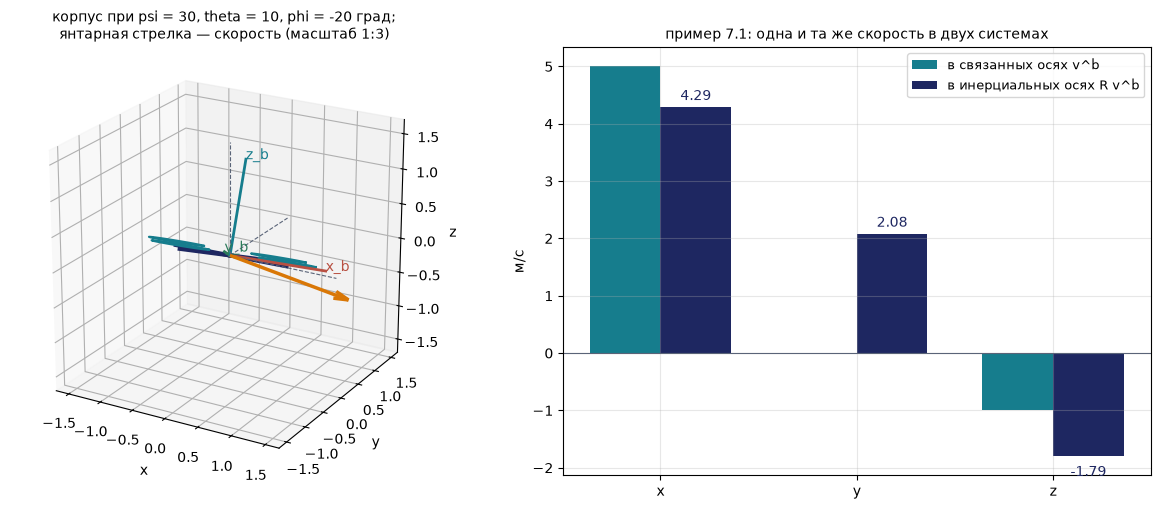

In [2]:
psi, th, phi = rad(30.0), rad(10.0), rad(-20.0)
R = R321(psi, th, phi); vb = np.array([5.0, 0.0, -1.0]); v = R.dot(vb)
print('R =\n', R.round(3))
print('v^b =', vb, ' ->  dp/dt = R v^b =', v.round(2), 'м/с')
print('модуль: |v^b| = %.2f, |dp/dt| = %.2f м/с;  вклад опущенного носа: -5 sin(10 град) = %.2f м/с' % (np.linalg.norm(vb), np.linalg.norm(v), -5*np.sin(th)))
print('ортогональность: max |R^T R - E| = %.1e;  det R = %.6f' % (np.abs(R.T.dot(R) - np.eye(3)).max(), np.linalg.det(R)))
print('углы по матрице (psi, theta, phi), град:', deg(np.array(euler321(R))).round(6))
print('третий столбец R — орт оси тяги z_b в инерциальной системе:', R[:, 2].round(3))

fig = plt.figure(figsize=(12.5, 5.2))
ax = fig.add_subplot(1, 2, 1, projection='3d'); draw_quad(ax, R); ax.view_init(22, -60)
ax.quiver(0, 0, 0, *(v/3.0), color=AMB, lw=2.5, arrow_length_ratio=0.12)
ax.set_title('корпус при psi = 30, theta = 10, phi = -20 град;\nянтарная стрелка — скорость (масштаб 1:3)', fontsize=10)
ax = fig.add_subplot(1, 2, 2); w = 0.36; k = np.arange(3)
ax.bar(k - w/2, vb, w, color=TEAL, label='в связанных осях v^b'); ax.bar(k + w/2, v, w, color=NAVY, label='в инерциальных осях R v^b')
for i in range(3): ax.text(i + w/2, v[i] + (0.12 if v[i] > 0 else -0.35), '%.2f' % v[i], ha='center', fontsize=10, color=NAVY)
ax.set_xticks(k); ax.set_xticklabels(['x', 'y', 'z']); ax.axhline(0, color=GREY, lw=.8); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_ylabel('м/с')
ax.set_title('пример 7.1: одна и та же скорость в двух системах', fontsize=10)
plt.tight_layout(); plt.show()

## 2. Матрица $W$ и её вырождение при тангаже $90^\circ$ (§ 7.3, пример 7.2)

$\dot{\boldsymbol\Theta}=W(\phi,\theta)\,\boldsymbol\omega^b$, $\boldsymbol\Theta=(\phi,\theta,\psi)^{\mathrm T}$; определитель прямой матрицы равен $\cos\theta$.
Ожидаем при $\boldsymbol\omega^b=(0{,}1;\,0{,}2;\,0{,}3)$ рад/с и $\phi=20^\circ$: для $\theta=60^\circ$ — $\dot{\boldsymbol\Theta}=(0{,}707;\ 0{,}085;\ 0{,}701)$; для $85^\circ$ — $\dot\phi=4{,}10$, $\dot\psi=4{,}02$ рад/с; спектральная норма $W$: $2{,}7;\ 8{,}1;\ 16{,}2$ при $60^\circ, 80^\circ, 85^\circ$ и $81$ при $89^\circ$.

W(20, 60 град) =
 [[ 1.     0.592  1.628]
 [ 0.     0.94  -0.342]
 [ 0.     0.684  1.879]]
проверка: W * Wdirect = E, max ошибка 8.8e-17;  det Wdirect = 0.5000 = cos(60 град)

 тангаж |  dphi    dtheta   dpsi , рад/с | норма W
    0   |   0.100   0.085   0.350        |    1.0
   30   |   0.302   0.085   0.405        |    1.4
   60   |   0.707   0.085   0.701        |    2.7
   80   |   2.087   0.085   2.017        |    8.1
   85   |   4.104   0.085   4.019        |   16.2
   89   |  20.169   0.085  20.072        |   81.0
наибольшая норма W при наклонах до 40 град: 1.67


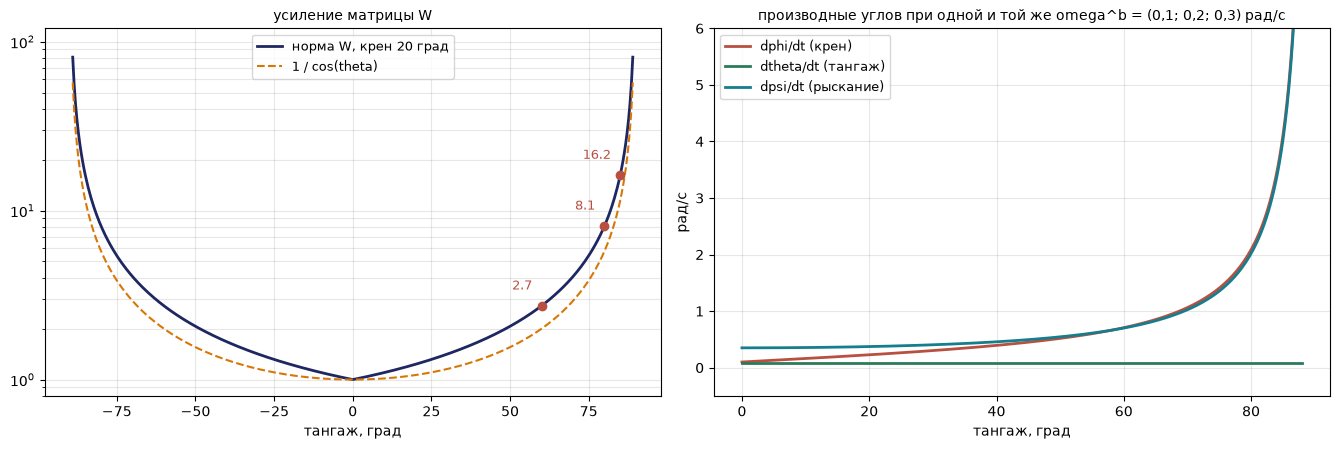

In [3]:
w = np.array([0.1, 0.2, 0.3]); ph = rad(20.0)
print('W(20, 60 град) =\n', Wmat(ph, rad(60)).round(3))
print('проверка: W * Wdirect = E, max ошибка %.1e;  det Wdirect = %.4f = cos(60 град)' % (np.abs(Wmat(ph, rad(60)).dot(Wdirect(ph, rad(60))) - np.eye(3)).max(), np.linalg.det(Wdirect(ph, rad(60)))))
print('\n тангаж |  dphi    dtheta   dpsi , рад/с | норма W')
for t in (0, 30, 60, 80, 85, 89):
    r = Wmat(ph, rad(t)).dot(w); print('  %3d   | %7.3f %7.3f %7.3f        | %6.1f' % (t, r[0], r[1], r[2], np.linalg.norm(Wmat(ph, rad(t)), 2)))
print('наибольшая норма W при наклонах до 40 град: %.2f' % max(np.linalg.norm(Wmat(rad(a), rad(b)), 2) for a in range(0, 41, 5) for b in range(0, 41, 5)))

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.6))
tt = np.linspace(-89, 89, 400); ax = axs[0]
ax.semilogy(tt, [np.linalg.norm(Wmat(ph, rad(t)), 2) for t in tt], color=NAVY, lw=2, label='норма W, крен 20 град')
ax.semilogy(tt, 1/np.cos(rad(tt)), color=AMB, lw=1.5, ls='--', label='1 / cos(theta)')
for t in (60, 80, 85):
    n_ = np.linalg.norm(Wmat(ph, rad(t)), 2); ax.plot(t, n_, 'o', color=RED); ax.text(t - 3, n_*1.25, '%.1f' % n_, color=RED, ha='right', fontsize=9)
ax.set_ylim(0.8, 120); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=9, loc='upper center'); ax.set_xlabel('тангаж, град'); ax.set_title('усиление матрицы W', fontsize=10)
td = np.linspace(0, 88, 300); rates = np.array([Wmat(ph, rad(t)).dot(w) for t in td]); ax = axs[1]
for j, (c, n_) in enumerate(((RED, 'dphi/dt (крен)'), (GREEN, 'dtheta/dt (тангаж)'), (TEAL, 'dpsi/dt (рыскание)'))): ax.plot(td, rates[:, j], color=c, lw=2, label=n_)
ax.set_ylim(-0.5, 6); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('тангаж, град'); ax.set_ylabel('рад/с')
ax.set_title('производные углов при одной и той же omega^b = (0,1; 0,2; 0,3) рад/с', fontsize=10)
plt.tight_layout(); plt.show()

## 3. Счисление ориентации тремя способами (§ 7.4)

Манёвр «петля»: $\boldsymbol\omega^b(t)=(0{,}2\sin1{,}3t;\ 0{,}8;\ 0{,}1\cos t)$ рад/с, шаг $h=0{,}01$ с, 20 с, метод Эйлера первого порядка:
углы $\boldsymbol\Theta\leftarrow\boldsymbol\Theta+hW\boldsymbol\omega^b$; матрица $R\leftarrow R(E+h\Lambda(\boldsymbol\omega^b))$ с ортогонализацией через сингулярное разложение; кватернион $\mathbf e\leftarrow\mathbf e+\frac h2\mathbf e\otimes\boldsymbol\omega^b$ с нормировкой. Эталон — шаг в 20 раз меньше и точная матричная экспонента.
Ожидаем: ошибка углов Эйлера до $1{,}80^\circ$, матрицы и кватерниона — до $0{,}16^\circ$; без коррекции $\lVert R^{\mathrm T}R-E\rVert=0{,}18$, дрейф нормы кватерниона $0{,}017$; наибольший тангаж $89{,}7^\circ$.

наибольшая ошибка, град:  углы Эйлера 1.80 (t = 7.42 с) | матрица 0.16 | кватернион 0.16
без коррекции за 20 с:  ||R^T R - E|| = 0.18,  | ||e|| - 1 | = 0.017
наибольший |тангаж| эталона: 89.7 град;  пики |тангажа|, град: [78.7 74.4 81.9 73.1 89.7] в моменты [ 1.9  6.   9.9 14.1 18. ] с


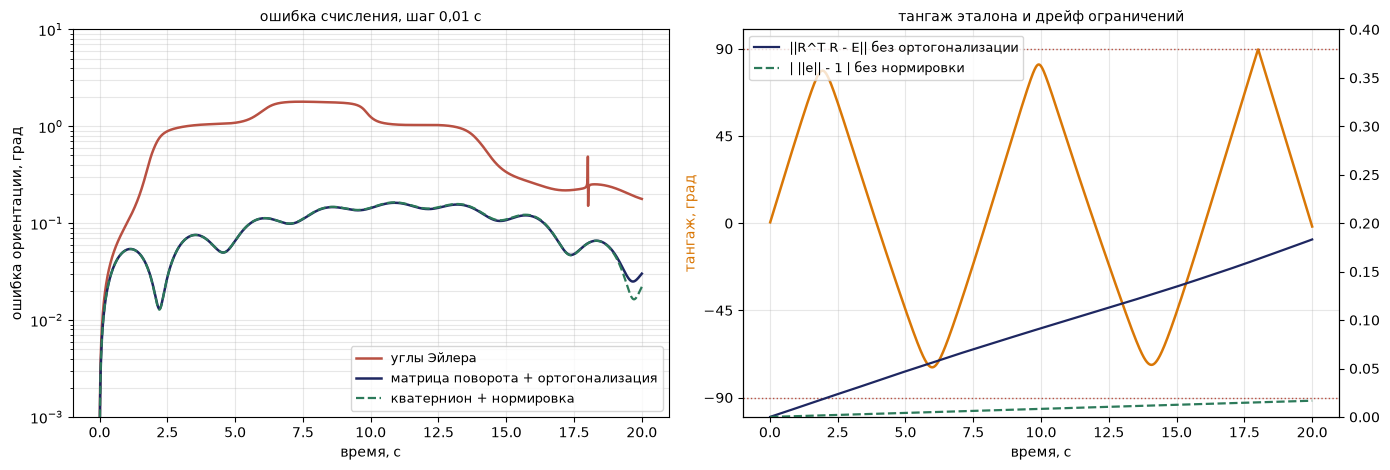

In [4]:
o = integrate_orientation(h=0.01, T=20.0, sub=20)
i_e = np.argmax(o[:, 2])
print('наибольшая ошибка, град:  углы Эйлера %.2f (t = %.2f с) | матрица %.2f | кватернион %.2f' % (o[:, 2].max(), o[i_e, 0], o[:, 3].max(), o[:, 4].max()))
print('без коррекции за 20 с:  ||R^T R - E|| = %.2f,  | ||e|| - 1 | = %.3f' % (o[-1, 5], o[-1, 6]))
a_ = np.abs(o[:, 1]); pk = [i for i in range(1, len(a_) - 1) if a_[i] > a_[i-1] and a_[i] >= a_[i+1] and a_[i] > 60]
print('наибольший |тангаж| эталона: %.1f град;  пики |тангажа|, град:' % a_.max(), a_[pk].round(1), 'в моменты', o[pk, 0].round(1), 'с')

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8)); ax = axs[0]
ax.semilogy(o[:, 0], o[:, 2], color=RED, lw=1.8, label='углы Эйлера')
ax.semilogy(o[:, 0], o[:, 3], color=NAVY, lw=1.8, label='матрица поворота + ортогонализация')
ax.semilogy(o[:, 0], o[:, 4], color=GREEN, lw=1.6, ls='--', label='кватернион + нормировка')
ax.set_ylim(1e-3, 10); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=9, loc='lower right'); ax.set_xlabel('время, с'); ax.set_ylabel('ошибка ориентации, град')
ax.set_title('ошибка счисления, шаг 0,01 с', fontsize=10)
ax = axs[1]; ax.plot(o[:, 0], o[:, 1], color=AMB, lw=1.8); ax.axhline(90, color=RED, ls=':', lw=1); ax.axhline(-90, color=RED, ls=':', lw=1)
ax.set_ylim(-100, 100); ax.set_yticks([-90, -45, 0, 45, 90]); ax.set_ylabel('тангаж, град', color=AMB); ax.set_xlabel('время, с'); ax.grid(alpha=.3)
ax2 = ax.twinx(); ax2.plot(o[:, 0], o[:, 5], color=NAVY, lw=1.6, label='||R^T R - E|| без ортогонализации'); ax2.plot(o[:, 0], o[:, 6], color=GREEN, lw=1.6, ls='--', label='| ||e|| - 1 | без нормировки')
ax2.set_ylim(0, 0.4); ax2.legend(fontsize=9, loc='upper left'); ax.set_title('тангаж эталона и дрейф ограничений', fontsize=10)
plt.tight_layout(); plt.show()

## 4. Матрица смешивания квадрокоптера «X», её обращение и насыщение моторов (§ 7.5, примеры 7.3 и 7.4)

$\mathbf u=M\mathbf f$, $\mathbf u=(T,\tau_x,\tau_y,\tau_z)^{\mathrm T}$; строки $M$ ортогональны, поэтому $M^{-1}=M^{\mathrm T}D^{-1}$, $D=\operatorname{diag}(4,4d^2,4d^2,4\kappa^2)$.
Ожидаем: для $\mathbf u=(4{,}905;\ 0{,}05;\ 0;\ 0{,}01)$ тяги $\mathbf f=(1{,}02;\ 1{,}23;\ 1{,}43;\ 1{,}23)$ Н; пределы моментов в висении $0{,}61$ и $0{,}12$ Н·м; запрос $\tau_z=0{,}15$ Н·м даёт отрицательные тяги $f_1=f_2=1{,}226-1{,}527$.

d = L / sqrt(2) = 0.1237 м, kappa = k_M / k_F = 0.02455 м, f_h = 1.2263 Н, f_max = 2.4525 Н, обороты висения 4480 об/мин
M =
 [[ 1.      1.      1.      1.    ]
 [-0.1237  0.1237  0.1237 -0.1237]
 [-0.1237  0.1237 -0.1237  0.1237]
 [-0.0245 -0.0245  0.0245  0.0245]] 
M M^T = diag [4.     0.0612 0.0612 0.0024] ;  вне диагонали max = 1.9e-20
M^-1 по формуле M^T D^-1 совпадает с численным обращением: True
схема «+»: M =
 [[ 1.      1.      1.      1.    ]
 [ 0.      0.175   0.     -0.175 ]
 [-0.175  -0.      0.175  -0.    ]
 [ 0.0245 -0.0245  0.0245 -0.0245]]

Пример 7.3: u = [4.905 0.05  0.    0.01 ] 
  поправки: tau_x/(4d) = 0.101 Н, tau_z/(4 kappa) = 0.102 Н
  f = M^-1 u = [1.02 1.23 1.43 1.23] Н;  сумма = 4.905 Н;  обороты: [4093. 4478. 4836. 4481.]

Пример 7.4: пределы в висении  tau_x = 4 d f_h = 0.61 Н*м,  tau_z = 4 kappa f_h = 0.12 Н*м
запрос tau_z = 0,15:
  f без ограничений = [-0.301 -0.301  2.754  2.754] 
  f после обрезания = [0.    0.    2.452 2.452] 
  запрошено u = [4.905 0

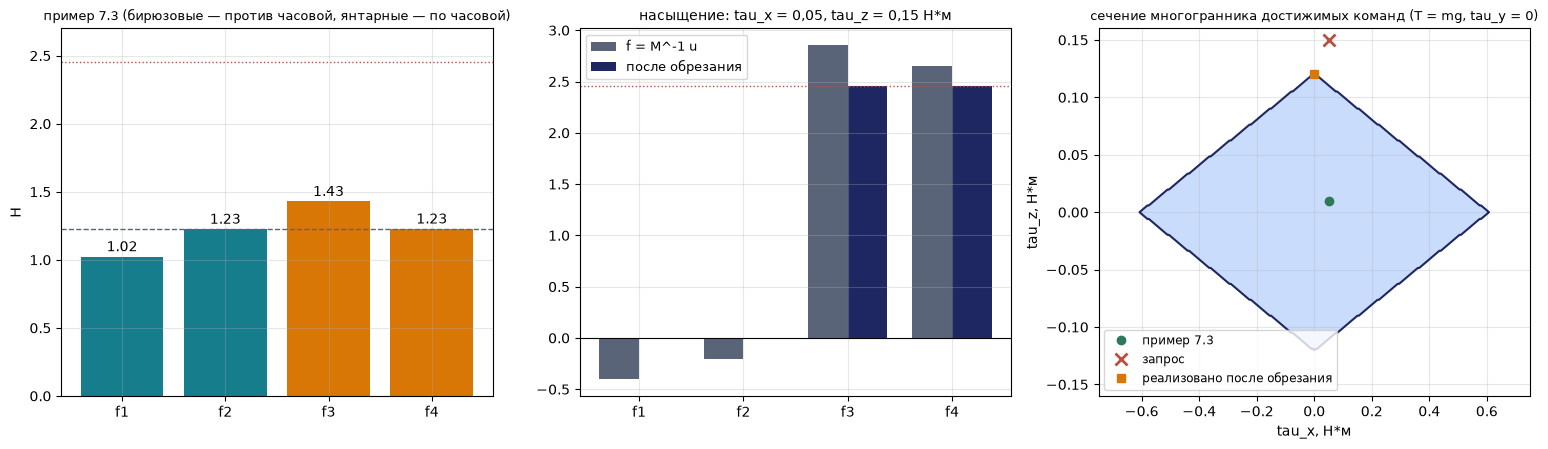

In [5]:
M = mixer_x(); Mi = mixer_x_inv()
print('d = L / sqrt(2) = %.4f м, kappa = k_M / k_F = %.5f м, f_h = %.4f Н, f_max = %.4f Н, обороты висения %.0f об/мин' % (D_Q, KAPPA, F_HOVER, F_MAX, np.sqrt(F_HOVER/K_F)))
print('M =\n', M.round(4), '\nM M^T = diag', np.diag(M.dot(M.T)).round(5), ';  вне диагонали max = %.1e' % np.abs(M.dot(M.T) - np.diag(np.diag(M.dot(M.T)))).max())
print('M^-1 по формуле M^T D^-1 совпадает с численным обращением: %s' % np.allclose(Mi, np.linalg.inv(M)))
print('схема «+»: M =\n', mixer_plus().round(4))
u = np.array([M_Q*G, 0.05, 0.0, 0.01])
print('\nПример 7.3: u =', u, '\n  поправки: tau_x/(4d) = %.3f Н, tau_z/(4 kappa) = %.3f Н' % (u[1]/(4*D_Q), u[3]/(4*KAPPA)))
f = Mi.dot(u); print('  f = M^-1 u =', f.round(2), 'Н;  сумма = %.3f Н;  обороты:' % f.sum(), np.sqrt(f/K_F).round(0))
print('\nПример 7.4: пределы в висении  tau_x = 4 d f_h = %.2f Н*м,  tau_z = 4 kappa f_h = %.2f Н*м' % (4*D_Q*F_HOVER, 4*KAPPA*F_HOVER))
for name, uu in (('запрос tau_z = 0,15', [M_Q*G, 0, 0, 0.15]), ('запрос tau_x = 0,05 и tau_z = 0,15', [M_Q*G, 0.05, 0, 0.15])):
    fr, fc, ur = allocate(np.array(uu)); print('%s:\n  f без ограничений =' % name, fr.round(3), '\n  f после обрезания =', fc.round(3), '\n  запрошено u =', np.array(uu).round(3), '\n  реализовано M f =', ur.round(3))

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.6)); k = np.arange(4); ax = axs[0]
ax.bar(k, f, color=[TEAL, TEAL, AMB, AMB]); ax.axhline(F_HOVER, color=GREY, ls='--', lw=1); ax.axhline(F_MAX, color=RED, ls=':', lw=1)
for i in range(4): ax.text(i, f[i] + 0.04, '%.2f' % f[i], ha='center', fontsize=10)
ax.set_xticks(k); ax.set_xticklabels(['f1', 'f2', 'f3', 'f4']); ax.set_ylabel('Н'); ax.set_ylim(0, 2.7); ax.grid(alpha=.3)
ax.set_title('пример 7.3 (бирюзовые — против часовой, янтарные — по часовой)', fontsize=9.5)
fr, fc, ur = allocate(np.array([M_Q*G, 0.05, 0, 0.15])); ax = axs[1]; w_ = 0.38
ax.bar(k - w_/2, fr, w_, color=GREY, label='f = M^-1 u'); ax.bar(k + w_/2, fc, w_, color=NAVY, label='после обрезания')
ax.axhline(0, color='k', lw=.8); ax.axhline(F_MAX, color=RED, ls=':', lw=1); ax.set_xticks(k); ax.set_xticklabels(['f1', 'f2', 'f3', 'f4']); ax.grid(alpha=.3); ax.legend(fontsize=9)
ax.set_title('насыщение: tau_x = 0,05, tau_z = 0,15 Н*м', fontsize=10)
tx = np.linspace(-0.75, 0.75, 301); tz = np.linspace(-0.16, 0.16, 301); TX, TZ = np.meshgrid(tx, tz); ok = np.ones_like(TX, bool)
for i in range(4):
    fi = Mi[i, 0]*M_Q*G + Mi[i, 1]*TX + Mi[i, 3]*TZ; ok &= (fi >= 0) & (fi <= F_MAX)
ax = axs[2]; ax.contourf(TX, TZ, ok.astype(float), levels=[0.5, 1.5], colors=[ICE]); ax.contour(TX, TZ, ok.astype(float), levels=[0.5], colors=[NAVY])
ax.plot(0.05, 0.01, 'o', color=GREEN, label='пример 7.3'); ax.plot(0.05, 0.15, 'x', color=RED, ms=9, mew=2, label='запрос'); ax.plot(ur[1], ur[3], 's', color=AMB, label='реализовано после обрезания')
ax.set_xlabel('tau_x, Н*м'); ax.set_ylabel('tau_z, Н*м'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='lower left')
ax.set_title('сечение многогранника достижимых команд (T = mg, tau_y = 0)', fontsize=9.5)
plt.tight_layout(); plt.show()

## 5. Полёт квадрокоптера по модели «наклон — ускорение» с каскадным регулятором (§ 7.6, пример 7.5)

Внешний контур: $\ddot{\mathbf p}_d=\ddot{\mathbf p}^{\ast}+K_d(\dot{\mathbf p}^{\ast}-\dot{\mathbf p})+K_p(\mathbf p^{\ast}-\mathbf p)$, $K_p=2$ с$^{-2}$, $K_d=2{,}5$ с$^{-1}$; затем $\theta_d=(\ddot x_dc_\psi+\ddot y_ds_\psi)/g$, $\phi_d=(\ddot x_ds_\psi-\ddot y_dc_\psi)/g$ с ограничением $20^\circ$. Внутренний контур заменён инерционным звеном с постоянной времени $0{,}15$ с. Корпус: $m\ddot{\mathbf p}=-mg\mathbf z_0+TR\mathbf z_0$.
Ожидаем для окружности $\rho=2$ м, период 10 с: скорость $1{,}26$ м/с, $a=0{,}79$ м/с$^2$, наклон $a/g=0{,}080$ рад ($4{,}6^\circ$), $\theta_d=-0{,}080\cos0{,}628t$, $\phi_d=0{,}080\sin0{,}628t$.

окружность: omega = 0.628 рад/с, скорость 1.26 м/с, a = 0.79 м/с^2, наклон a/g = 0.080 рад = 4.6 град


установившийся режим: амплитуда тангажа 0.0811 рад, крена 0.0811 рад, полный наклон 0.0811 рад (4.65 град)
ошибка слежения по окружности: 0.033 м;  радиус фактической траектории 2.020 м
квадрат 4 x 4 м, 1 м/с: наибольшая ошибка 0.48 м, наибольший наклон 11.5 град (ограничение 20)


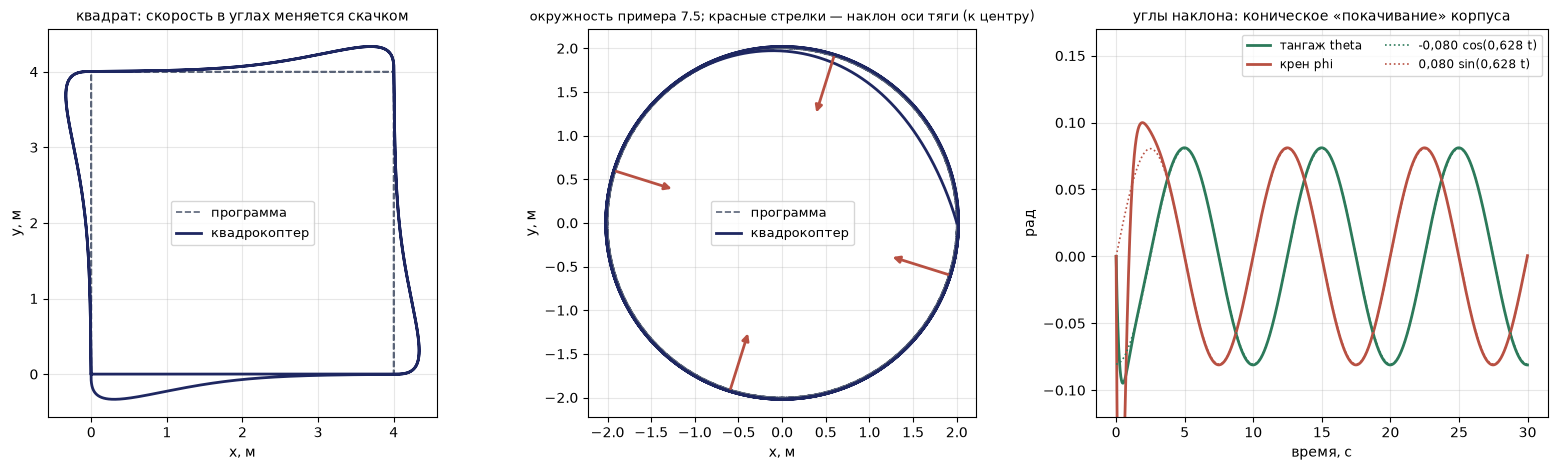

In [6]:
wc = 2*np.pi/10; a_c = wc**2*2.0
print('окружность: omega = %.3f рад/с, скорость %.2f м/с, a = %.2f м/с^2, наклон a/g = %.3f рад = %.1f град' % (wc, wc*2, a_c, a_c/G, deg(a_c/G)))
c = simulate_quad(ref_circle(2.0, 10.0), T=30.0); s = simulate_quad(ref_square(4.0, 1.0), T=32.0)
st = c['t'] > 10
tilt = np.arccos(np.cos(c['phi'])*np.cos(c['theta']))
print('установившийся режим: амплитуда тангажа %.4f рад, крена %.4f рад, полный наклон %.4f рад (%.2f град)' % (np.abs(c['theta'][st]).max(), np.abs(c['phi'][st]).max(), tilt[st].mean(), deg(tilt[st].mean())))
print('ошибка слежения по окружности: %.3f м;  радиус фактической траектории %.3f м' % (np.linalg.norm((c['p'] - c['pref'])[st, :2], axis=1).max(), np.hypot(c['p'][st, 0], c['p'][st, 1]).mean()))
print('квадрат 4 x 4 м, 1 м/с: наибольшая ошибка %.2f м, наибольший наклон %.1f град (ограничение 20)' % (np.linalg.norm((s['p'] - s['pref'])[:, :2], axis=1).max(), deg(max(np.abs(s['theta']).max(), np.abs(s['phi']).max()))))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8)); ax = axs[0]
ax.plot(s['pref'][:, 0], s['pref'][:, 1], color=GREY, ls='--', lw=1.2, label='программа'); ax.plot(s['p'][:, 0], s['p'][:, 1], color=NAVY, lw=2, label='квадрокоптер')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='center'); ax.set_title('квадрат: скорость в углах меняется скачком', fontsize=10); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax = axs[1]; ax.plot(c['pref'][:, 0], c['pref'][:, 1], color=GREY, ls='--', lw=1.2, label='программа'); ax.plot(c['p'][:, 0], c['p'][:, 1], color=NAVY, lw=2, label='квадрокоптер')
for tk in (12.0, 14.5, 17.0, 19.5):
    i = int(tk/0.005); zb = R321(0, c['theta'][i], c['phi'][i])[:, 2]
    ax.annotate('', xy=(c['p'][i, 0] + 9*zb[0], c['p'][i, 1] + 9*zb[1]), xytext=(c['p'][i, 0], c['p'][i, 1]), arrowprops=dict(arrowstyle='-|>', color=RED, lw=2))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='center'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title('окружность примера 7.5; красные стрелки — наклон оси тяги (к центру)', fontsize=9.5)
ax = axs[2]; ax.plot(c['t'], c['theta'], color=GREEN, lw=2, label='тангаж theta'); ax.plot(c['t'], c['phi'], color=RED, lw=2, label='крен phi')
ax.plot(c['t'], -a_c/G*np.cos(wc*c['t']), color=GREEN, ls=':', lw=1.2, label='-0,080 cos(0,628 t)'); ax.plot(c['t'], a_c/G*np.sin(wc*c['t']), color=RED, ls=':', lw=1.2, label='0,080 sin(0,628 t)')
ax.grid(alpha=.3); ax.legend(fontsize=8.5, ncol=2, loc='upper right'); ax.set_ylim(-0.12, 0.17); ax.set_xlabel('время, с'); ax.set_ylabel('рад'); ax.set_title('углы наклона: коническое «покачивание» корпуса', fontsize=10)
plt.tight_layout(); plt.show()

## 6. Координированный разворот самолёта (§ 7.7)

$\lvert\dot\psi\rvert=\dfrac gV\operatorname{tg}\lvert\phi\rvert$, $R=\dfrac{V^2}{g\operatorname{tg}\lvert\phi\rvert}$, перегрузка $1/\cos\phi$.
Ожидаем при $V=20$ м/с и $\phi=30^\circ$: $\dot\psi=0{,}283$ рад/с $=16{,}2^\circ$/с, $R=70{,}6$ м, перегрузка $1{,}15$; при 40 м/с — 282 м.

V = 20 м/с, крен 30 град: dpsi/dt = 0.283 рад/с = 16.2 град/с,  R = 70.6 м,  перегрузка 1/cos(phi) = 1.15
V = 40 м/с, крен 30 град: dpsi/dt = 8.1 град/с,  R = 282 м


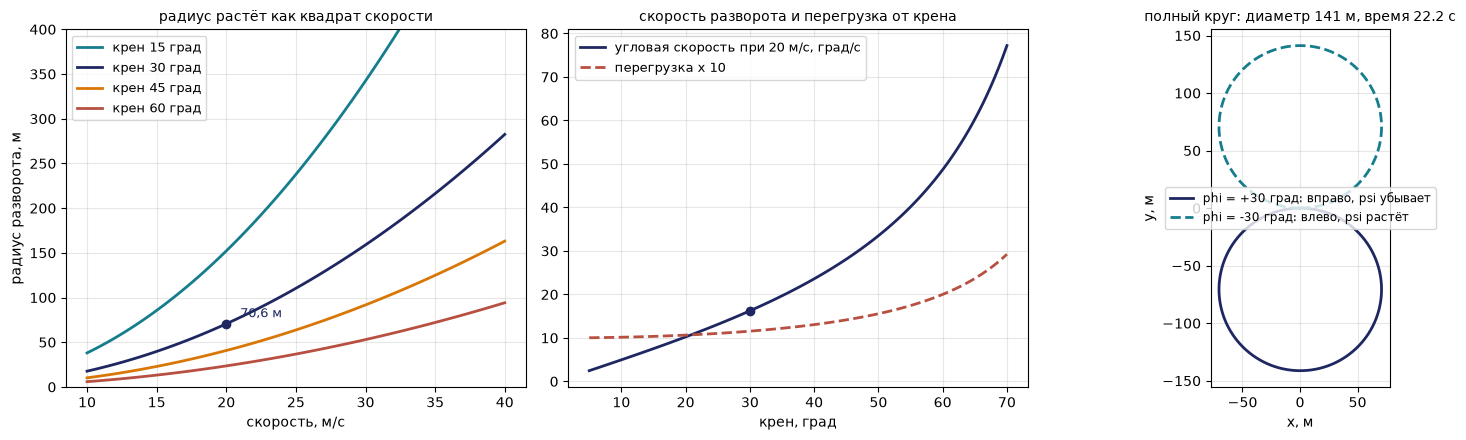

In [7]:
V, ph = 20.0, rad(30.0)
print('V = 20 м/с, крен 30 град: dpsi/dt = %.3f рад/с = %.1f град/с,  R = %.1f м,  перегрузка 1/cos(phi) = %.2f' % (turn_rate(V, ph), deg(turn_rate(V, ph)), turn_radius(V, ph), 1/np.cos(ph)))
print('V = 40 м/с, крен 30 град: dpsi/dt = %.1f град/с,  R = %.0f м' % (deg(turn_rate(40.0, ph)), turn_radius(40.0, ph)))
fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.5)); vv = np.linspace(10, 40, 100); ax = axs[0]
for p_, c_ in ((15, TEAL), (30, NAVY), (45, AMB), (60, RED)): ax.plot(vv, turn_radius(vv, rad(p_)), color=c_, lw=2, label='крен %d град' % p_)
ax.plot(20, turn_radius(20, ph), 'o', color=NAVY); ax.text(21, 78, '70,6 м', color=NAVY, fontsize=9)
ax.set_ylim(0, 400); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('скорость, м/с'); ax.set_ylabel('радиус разворота, м'); ax.set_title('радиус растёт как квадрат скорости', fontsize=10)
pp = np.linspace(5, 70, 100); ax = axs[1]; ax.plot(pp, deg(turn_rate(20.0, rad(pp))), color=NAVY, lw=2, label='угловая скорость при 20 м/с, град/с')
ax.plot(pp, 10/np.cos(rad(pp)), color=RED, lw=2, ls='--', label='перегрузка x 10'); ax.plot(30, 16.2, 'o', color=NAVY); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('крен, град')
ax.set_title('скорость разворота и перегрузка от крена', fontsize=10)
ax = axs[2]; R_ = turn_radius(V, ph)
xy = simulate_plane(V, lambda t, p: -turn_rate(V, ph)*t, T=2*np.pi/turn_rate(V, ph), dt=0.02)
ax.plot(xy[:, 0], xy[:, 1], color=NAVY, lw=2, label='phi = +30 град: вправо, psi убывает')
xy2 = simulate_plane(V, lambda t, p: +turn_rate(V, ph)*t, T=2*np.pi/turn_rate(V, ph), dt=0.02); ax.plot(xy2[:, 0], xy2[:, 1], color=TEAL, lw=2, ls='--', label='phi = -30 град: влево, psi растёт')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='center'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title('полный круг: диаметр %.0f м, время %.1f с' % (2*R_, 2*np.pi/turn_rate(V, ph)), fontsize=10)
plt.tight_layout(); plt.show()

## 7. Треугольник скоростей и снос ветром (§ 7.7, пример 7.6)

$\mathbf V_g=\mathbf V_a+\mathbf V_w$. Линия пути — ось $x$, $V_a=20$ м/с, ветер 6 м/с вдоль $y$: $V_a\sin\psi=-6$.
Ожидаем: курс $\psi=-17{,}5^\circ$, путевая скорость $19{,}1$ м/с; без поправки аппарат сносит на 6 м каждую секунду.

курс с поправкой на ветер: psi = -17.5 град;  путевая скорость Vg = 19.1 м/с;  угол сноса chi - psi = 17.5 град
без поправки (psi = 0): путевой угол chi = 16.7 град, путевая скорость 20.9 м/с, боковой снос за 30 с = 180 м
контрольный вопрос 13 (25 м/с, ветер 8 м/с): psi = -18.7 град, Vg = 23.7 м/с


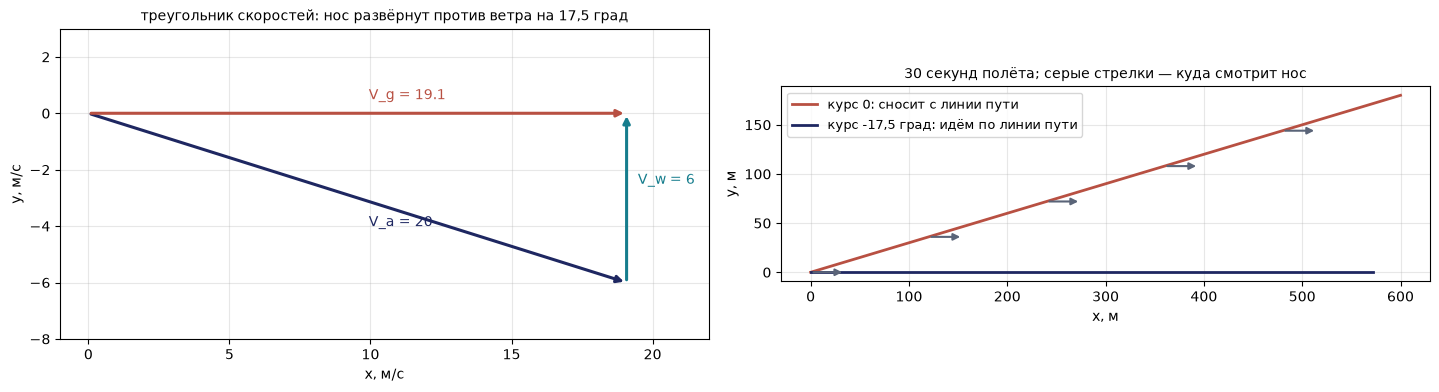

In [8]:
Va, wind = 20.0, (0.0, 6.0)
psi_c, Vg = crab_angle(Va, wind, chi=0.0)
print('курс с поправкой на ветер: psi = %.1f град;  путевая скорость Vg = %.1f м/с;  угол сноса chi - psi = %.1f град' % (deg(psi_c), Vg, -deg(psi_c)))
print('без поправки (psi = 0): путевой угол chi = %.1f град, путевая скорость %.1f м/с, боковой снос за 30 с = %.0f м' % (deg(np.arctan2(6, 20)), np.hypot(20, 6), 6*30))
psi_q, Vg_q = crab_angle(25.0, (0.0, 8.0)); print('контрольный вопрос 13 (25 м/с, ветер 8 м/с): psi = %.1f град, Vg = %.1f м/с' % (deg(psi_q), Vg_q))
xy0 = simulate_plane(Va, lambda t, p: 0.0, wind, T=30); xy1 = simulate_plane(Va, lambda t, p: psi_c, wind, T=30)
fig, axs = plt.subplots(1, 2, figsize=(14.5, 4.6)); ax = axs[0]
for v0, v1, c_, n_ in (((0, 0), (Va*np.cos(psi_c), Va*np.sin(psi_c)), NAVY, 'V_a = 20'), ((Va*np.cos(psi_c), Va*np.sin(psi_c)), (Vg, 0), TEAL, 'V_w = 6'), ((0, 0), (Vg, 0), RED, 'V_g = %.1f' % Vg)):
    ax.annotate('', xy=v1, xytext=v0, arrowprops=dict(arrowstyle='-|>', color=c_, lw=2.2)); ax.text((v0[0] + v1[0])/2 + 0.4, (v0[1] + v1[1])/2 - (1.0 if c_ == NAVY else -0.5), n_, color=c_, fontsize=10)
ax.set_xlim(-1, 22); ax.set_ylim(-8, 3); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlabel('x, м/с'); ax.set_ylabel('y, м/с'); ax.set_title('треугольник скоростей: нос развёрнут против ветра на 17,5 град', fontsize=10)
ax = axs[1]; ax.plot(xy0[:, 0], xy0[:, 1], color=RED, lw=2, label='курс 0: сносит с линии пути'); ax.plot(xy1[:, 0], xy1[:, 1], color=NAVY, lw=2, label='курс -17,5 град: идём по линии пути')
for xy, ps in ((xy0, 0.0), (xy1, psi_c)):
    for i in range(0, len(xy), 120): ax.annotate('', xy=(xy[i, 0] + 35*np.cos(ps), xy[i, 1] + 35*np.sin(ps)), xytext=(xy[i, 0], xy[i, 1]), arrowprops=dict(arrowstyle='-|>', color=GREY, lw=1.5))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='upper left'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_title('30 секунд полёта; серые стрелки — куда смотрит нос', fontsize=10)
plt.tight_layout(); plt.show()

## 8. Пути Дубинса между двумя позами (§ 7.7, пример 7.7)

Модель: $\dot x=V\cos\psi$, $\dot y=V\sin\psi$, $\dot\psi=u$, $\lvert u\rvert\le V/R_{\min}$, $R_{\min}=70{,}6$ м. Перебираем шесть типов (LSL, RSR, LSR, RSL, RLR, LRL); каждый кандидат проверяется прямым построением.
Ожидаем: далёкие позы $(0,0,0^\circ)\to(400,250,180^\circ)$ — LSL 636 м (LSR 794, RSL 1080, RSR 1225 м; по прямой 472 м); близкие позы $(0,0,90^\circ)\to(90,0,-90^\circ)$ — LRL 395 м, RSR 717 м.

R_min = 70.6 м

далёкие позы: по прямой 472 м
  LSL:   636.3 м   (L 15 град, S 415 м, L 165 град)   <- кратчайший
  LSR:   793.7 м   (L 49 град, S 450 м, R 229 град)
  RSL:  1079.5 м   (R 345 град, S 450 м, L 165 град)
  RSR:  1224.9 м   (R 316 град, S 559 м, R 224 град)

близкие позы: по прямой 90 м
  LRL:   394.5 м   (L 35 град, R 250 град, L 35 град)   <- кратчайший
  RLR:   613.9 м   (R 80 град, L 339 град, R 80 град)
  RSR:   716.6 м   (R 270 град, S 51 м, R 270 град)
  LSL:   896.6 м   (L 270 град, S 231 м, L 270 град)


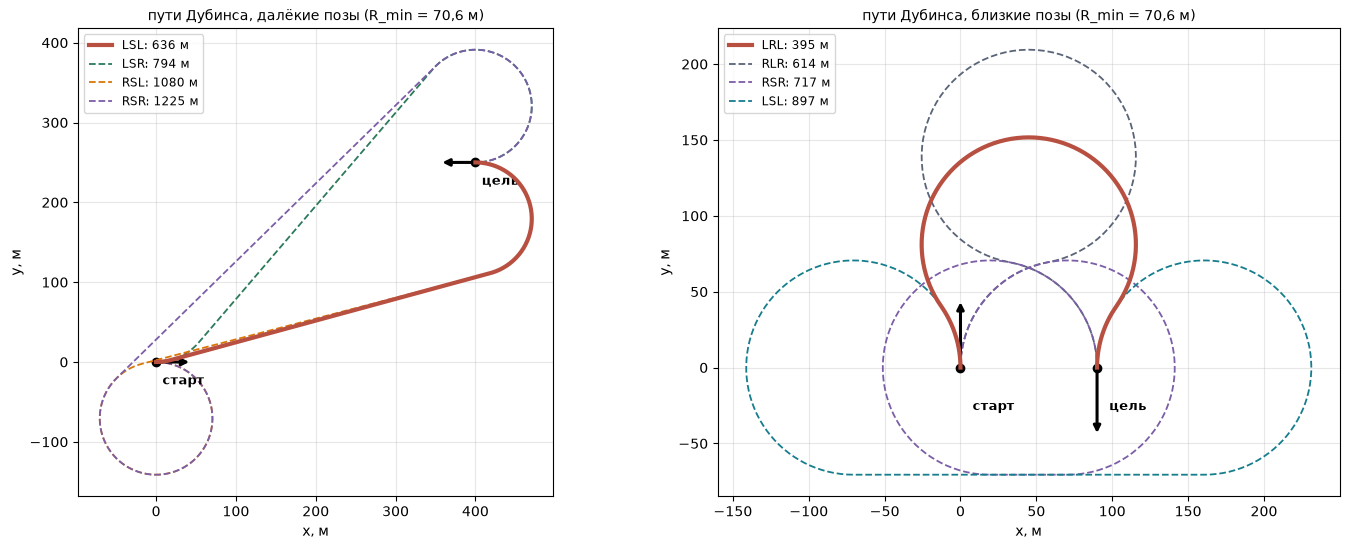

In [9]:
rho = turn_radius(20.0, rad(30.0)); print('R_min = %.1f м' % rho); rho = 70.6
cases = [((0.0, 0.0, 0.0), (400.0, 250.0, np.pi), 'далёкие позы'), ((0.0, 0.0, np.pi/2), (90.0, 0.0, -np.pi/2), 'близкие позы')]
cols = {'LSL': TEAL, 'RSR': '#7B5EA7', 'LSR': GREEN, 'RSL': AMB, 'RLR': GREY, 'LRL': NAVY}
fig, axs = plt.subplots(1, 2, figsize=(14.5, 5.6))
for ax, (st, go, ttl) in zip(axs, cases):
    paths = dubins_all(st, go, rho); print('\n%s: по прямой %.0f м' % (ttl, np.hypot(go[0] - st[0], go[1] - st[1])))
    for j, (Ln, wn, segs, xs, ys) in enumerate(paths):
        parts = ', '.join(('%s %.0f град' % (ch, deg(s_))) if ch != 'S' else ('S %.0f м' % (s_*rho)) for ch, s_ in zip(wn, segs))
        print('  %s: %7.1f м   (%s)%s' % (wn, Ln, parts, '   <- кратчайший' if j == 0 else ''))
        ax.plot(xs, ys, color=RED if j == 0 else cols[wn], lw=3 if j == 0 else 1.3, ls='-' if j == 0 else '--', zorder=6 if j == 0 else 3, label='%s: %.0f м' % (wn, Ln))
    for pose, n_ in ((st, 'старт'), (go, 'цель')):
        ax.annotate('', xy=(pose[0] + 45*np.cos(pose[2]), pose[1] + 45*np.sin(pose[2])), xytext=pose[:2], arrowprops=dict(arrowstyle='-|>', color='k', lw=2.2)); ax.plot(pose[0], pose[1], 'ko')
        ax.text(pose[0] + 8, pose[1] - 28, n_, fontsize=9.5, weight='bold')
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper left'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_title('пути Дубинса, %s (R_min = 70,6 м)' % ttl, fontsize=10)
plt.tight_layout(); plt.show()

## 9. Отказ мотора у квадрокоптера и у гексакоптера (§ 7.5)

При отказе мотора из матрицы смешивания вычёркивается столбец. Ожидаем: у квадрокоптера остаётся матрица $4\times3$ ранга 3, у гексакоптера — $4\times5$ ранга 4.
Но ранг — условие необходимое, а не достаточное: тяги должны лежать в пределах $0\le f_i\le f_{\max}$. Проверяем, остаётся ли команда висения $\mathbf u=(mg,0,0,0)$ достижимой и с каким запасом (наибольшее $s$, при котором $s\le f_i\le f_{\max}-s$; линейное программирование).

исправный квадрокоптер: ранг 4;  исправный гексакоптер: матрица 4x6, ранг 4, размерность ядра 2
  гексакоптер, висение: f = M^+ u = [0.818 0.818 0.818 0.818 0.818 0.818] Н; запас по тягам 0.817 Н

КВАДРОКОПТЕР, отказ мотора 1:
  матрица 4x3, ранг 3 -> четыре величины независимо не задать;  висение с tau_z = 0 достижимо: False
  жертвуем рысканием (строки T, tau_x, tau_y): f2, f3, f4 = [0.    2.452 2.452] Н (f_max = 2.453);  остаётся момент рыскания 0.120 Н*м — аппарат вращается

ГЕКСАКОПТЕР (направления вращения чередуются), отказ одного мотора:
  мотор 1: ранг 4; f = M^+ u = [ 1.23  1.23 -0.    1.23  1.23]; min = -0.000 Н; висение при f >= 0 достижимо: True, запас 0.000 Н
  мотор 2: ранг 4; f = M^+ u = [1.23 1.23 1.23 0.   1.23]; min = +0.000 Н; висение при f >= 0 достижимо: True, запас 0.000 Н
  мотор 3: ранг 4; f = M^+ u = [1.23 1.23 1.23 1.23 0.  ]; min = +0.000 Н; висение при f >= 0 достижимо: True, запас 0.000 Н
  мотор 4: ранг 4; f = M^+ u = [0.   1.23 1.23 1.23 1.23]; min = +0.

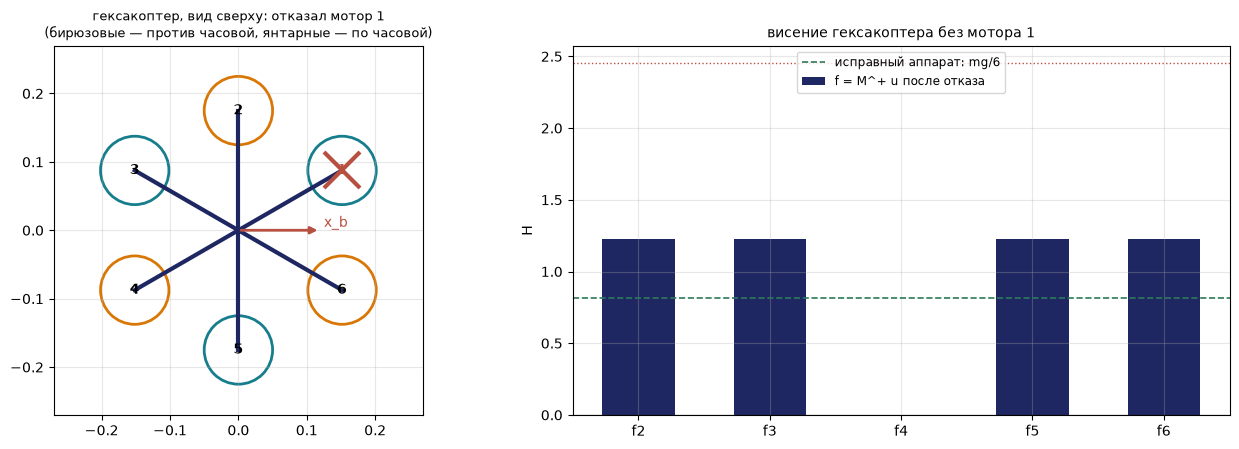

In [10]:
Mq = mixer_x(); xy6, sg6 = hexa_geometry(); Mh = mixer_general(xy6, sg6); W_ = M_Q*G; u_h = np.array([W_, 0, 0, 0.0])
print('исправный квадрокоптер: ранг %d;  исправный гексакоптер: матрица %dx%d, ранг %d, размерность ядра %d' % (np.linalg.matrix_rank(Mq), Mh.shape[0], Mh.shape[1], np.linalg.matrix_rank(Mh), 6 - np.linalg.matrix_rank(Mh)))
ok, f6, s6 = hover_feasible(Mh, W_, F_MAX); print('  гексакоптер, висение: f = M^+ u =', np.linalg.pinv(Mh).dot(u_h).round(3), 'Н; запас по тягам %.3f Н' % s6)
print('\nКВАДРОКОПТЕР, отказ мотора 1:'); Mq1 = np.delete(Mq, 0, axis=1)
print('  матрица 4x3, ранг %d -> четыре величины независимо не задать;  висение с tau_z = 0 достижимо: %s' % (np.linalg.matrix_rank(Mq1), hover_feasible(Mq1, W_, F_MAX)[0]))
f3 = np.linalg.solve(Mq1[:3], u_h[:3]); print('  жертвуем рысканием (строки T, tau_x, tau_y): f2, f3, f4 =', f3.round(3), 'Н (f_max = %.3f);  остаётся момент рыскания %.3f Н*м — аппарат вращается' % (F_MAX, Mq1[3].dot(f3)))
print('\nГЕКСАКОПТЕР (направления вращения чередуются), отказ одного мотора:')
for k in range(6):
    Mk = np.delete(Mh, k, axis=1); fp = np.linalg.pinv(Mk).dot(u_h); ok, fl, s = hover_feasible(Mk, W_, F_MAX)
    print('  мотор %d: ранг %d; f = M^+ u = %s; min = %+.3f Н; висение при f >= 0 достижимо: %s, запас %.3f Н' % (k + 1, np.linalg.matrix_rank(Mk), fp.round(2), fp.min(), ok, abs(s)))
print('  вывод: ранг 4 сохраняется, но мотор напротив отказавшего приходится выключить (его тяга равна нулю): команда висения')
print('  лежит НА ГРАНИЦЕ многогранника достижимых команд (запас 0), аппарат висит на четырёх моторах без запаса на манёвр.')

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.6)); ax = axs[0]
for i, (p_, s_) in enumerate(zip(xy6, sg6)):
    ax.plot([0, p_[0]], [0, p_[1]], color=NAVY, lw=3); ax.add_patch(plt.Circle(p_, 0.05, fc='white', ec=TEAL if s_ > 0 else AMB, lw=2)); ax.text(p_[0], p_[1], str(i + 1), ha='center', va='center', fontsize=10, color='k' if i else RED, weight='bold')
ax.plot(*xy6[0], 'x', color=RED, ms=26, mew=3); ax.annotate('', xy=(0.12, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=RED, lw=2)); ax.text(0.125, 0.005, 'x_b', color=RED)
ax.set_xlim(-0.27, 0.27); ax.set_ylim(-0.27, 0.27); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('гексакоптер, вид сверху: отказал мотор 1\n(бирюзовые — против часовой, янтарные — по часовой)', fontsize=9.5)
M1 = np.delete(Mh, 0, axis=1); fp = np.linalg.pinv(M1).dot(u_h); ok, fl, s = hover_feasible(M1, W_, F_MAX); k = np.arange(5); w_ = 0.38; ax = axs[1]
ax.bar(k, fp, 0.55, color=NAVY, label='f = M^+ u после отказа'); ax.axhline(W_/6, color=GREEN, ls='--', lw=1.2, label='исправный аппарат: mg/6')
ax.axhline(0, color='k', lw=.8); ax.axhline(F_MAX, color=RED, ls=':', lw=1); ax.set_xticks(k); ax.set_xticklabels(['f2', 'f3', 'f4', 'f5', 'f6']); ax.set_ylabel('Н'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper center')
ax.set_title('висение гексакоптера без мотора 1', fontsize=10)
plt.tight_layout(); plt.show()

## 10. Интерактив: углы рыскания, тангажа и крена, вектор тяги и горизонтальное ускорение (запускать вживую)

Корпус удерживает высоту: $T\,(\mathbf z_b)_z=mg$, поэтому горизонтальное ускорение равно $g\,(z_{b,x},\,z_{b,y})/z_{b,z}$; в заголовке оно сравнивается с линеаризованной моделью $\ddot x=g(\theta c_\psi+\phi s_\psi)$, $\ddot y=g(\theta s_\psi-\phi c_\psi)$. Красная стрелка — тяга, янтарная — горизонтальное ускорение.

In [11]:
def show_quad(psi=0.0, theta=15.0, phi=0.0):
    R = R321(rad(psi), rad(theta), rad(phi)); zb = R[:, 2]
    fig = plt.figure(figsize=(6.8, 6.2)); ax = fig.add_subplot(111, projection='3d'); ax.view_init(22, -60)
    if zb[2] <= 0.05:
        draw_quad(ax, R); ax.set_title('ось тяги горизонтальна или направлена вниз: высоту не удержать', color=RED, fontsize=10)
    else:
        acc = G*zb[:2]/zb[2]; lin = G*np.array([rad(theta)*np.cos(rad(psi)) + rad(phi)*np.sin(rad(psi)), rad(theta)*np.sin(rad(psi)) - rad(phi)*np.cos(rad(psi))])
        draw_quad(ax, R, thrust=1.5/zb[2], accel=acc/G*1.5)
        ax.set_title('тяга T = %.2f mg;  ускорение (x, y) = (%.2f; %.2f) м/с^2\nлинеаризованная модель: (%.2f; %.2f) м/с^2' % (1/zb[2], acc[0], acc[1], lin[0], lin[1]), fontsize=10, color=NAVY)
    plt.show()
try:
    from ipywidgets import interact, FloatSlider
    interact(show_quad, psi=FloatSlider(min=-180, max=180, step=5, value=0.0, description='рыскание'), theta=FloatSlider(min=-60, max=60, step=1, value=15.0, description='тангаж'), phi=FloatSlider(min=-60, max=60, step=1, value=0.0, description='крен'))
except ImportError:
    print('установите ipywidgets: pip install ipywidgets'); show_quad(30.0, 15.0, -10.0)

interactive(children=(FloatSlider(value=0.0, description='рыскание', max=180.0, min=-180.0, step=5.0), FloatSl…